In [1]:
#LIBRARIES
import random
from pathlib import Path
import numpy as np, wave
import pandas as pd
import torch
import torchaudio
import matplotlib.pyplot as plt
from tqdm import tqdm
from transformers import Wav2Vec2ForSequenceClassification, AutoFeatureExtractor
from config import CHILD, CHILD_AFR_SADILAR, ADULT_NCHLT, NOISY_DIR, RESULTS_DIR


#SET SEED AND SAMPLE_RATE
random.seed(42)
np.random.seed(42)
#MMS expects 16 kHz audio
SAMPLE_RATE = 16000

/Users/conarj/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
#IMPORT FACEBOOK MMS-LID MODEL
lid_model_id = "facebook/mms-lid-126"

#Retrieve feature extractor for LID model:
feature_extractor = AutoFeatureExtractor.from_pretrained(lid_model_id)

#wav2vec 2.0 encoder with a classification head over 126 languages
model = Wav2Vec2ForSequenceClassification.from_pretrained(lid_model_id)

#Load model on cpu
device = "cpu"

#eval() switches off dropout so the predictions are repeatable
lid_model = model.to(device).eval()
print(f"Model loaded on {device}")

Model loaded on cpu


In [3]:
#LOAD AND DESCRIBE AFR CHILD DATASET:
#Afrikaans from the Babaloon study, CHILD tier only
CHILD_MANIFEST_AFR, CHILD_AUDIO_DIR_AFR = CHILD["afr"]

#One row per segment: filename, speaker, start and end time
afr_child_df = pd.read_csv(CHILD_MANIFEST_AFR)
afr_child_df["path"] = afr_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_AFR / f)
afr_child_df["true_lang"] = "afr"   
print(f"Loaded {len(afr_child_df)} AFR audio segments.") 
#Segments per speaker
print(afr_child_df["speaker"].value_counts().describe())
afr_child_df["true_lang"] = "afr"

Loaded 13990 AFR audio segments.
count    154.000000
mean      90.844156
std       42.936209
min       26.000000
25%       60.000000
50%       84.000000
75%      112.750000
max      284.000000
Name: count, dtype: float64


In [4]:
#LOAD AND DESCRIBE ENGLISH CHILD DATASET : 
#British English from Nexdata, read speech
CHILD_MANIFEST_ENG, CHILD_AUDIO_DIR_ENG = CHILD["eng"]

eng_child_df = pd.read_csv(CHILD_MANIFEST_ENG)
#Each session has its own folder and the files are whole recordings, not cut segments
eng_child_df["path"] = eng_child_df.apply(
    lambda r: CHILD_AUDIO_DIR_ENG / r["session"] / r["filename"], axis=1
)
eng_child_df["true_lang"] = "eng"
print(f"Loaded {len(eng_child_df)} ENG audio segments.")
print(eng_child_df["session"].value_counts().describe())

Loaded 13160 ENG audio segments.
count     40.000000
mean     329.000000
std       54.322399
min       57.000000
25%      334.000000
50%      343.000000
75%      348.000000
max      350.000000
Name: count, dtype: float64


In [5]:
#LOAD AND DESCRIBE NORTHERN SOTHO CHILD DATASET : 
#Sesotho sa Leboa from the SADiLaR corpus
CHILD_MANIFEST_NSO, CHILD_AUDIO_DIR_NSO = CHILD["nso"]

nso_child_df = pd.read_csv(CHILD_MANIFEST_NSO)
nso_child_df["path"]       = nso_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_NSO / f)
nso_child_df["true_lang"] = "nso"
print(f"Loaded {len(nso_child_df)} NSO audio segments.")
print(nso_child_df["speaker"].value_counts().describe())

Loaded 10085 NSO audio segments.
count     27.000000
mean     373.518519
std       57.594318
min      261.000000
25%      328.500000
50%      372.000000
75%      408.500000
max      516.000000
Name: count, dtype: float64


In [ ]:
#LOAD AND DESCRIBE XHOSA DATA
#isiXhosa from the Babaloon study, CHILD tier only
CHILD_MANIFEST_XHO, CHILD_AUDIO_DIR_XHO = CHILD["xho"]

xho_child_df = pd.read_csv(CHILD_MANIFEST_XHO)
xho_child_df["path"] = xho_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_XHO / f)
xho_child_df["true_lang"] = "xho"
print(f"Loaded {len(xho_child_df)} XHO audio segments.")
print(xho_child_df["speaker"].value_counts().describe())

Loaded 12947 XHO audio segments.
count    153.000000
mean      84.620915
std       40.523873
min        3.000000
25%       53.000000
50%       84.000000
75%      109.000000
max      261.000000
Name: count, dtype: float64


In [ ]:
#LOAD AND DESCRIBE DUTCH DATASET
#Dutch from CHOREC, read speech
CHILD_MANIFEST_NLD, CHILD_AUDIO_DIR_NLD = CHILD["nld"]

nld_child_df = pd.read_csv(CHILD_MANIFEST_NLD)
nld_child_df["path"] = nld_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_NLD / f)
nld_child_df["true_lang"] = "nld" 
print(f"Loaded {len(nld_child_df)} NLD audio segments.")
print(nld_child_df["speaker"].value_counts().describe())

Loaded 16107 NLD audio segments.
count    168.000000
mean      95.875000
std       31.519063
min       40.000000
25%       80.000000
50%       80.000000
75%      108.250000
max      235.000000
Name: count, dtype: float64


In [8]:
#USE THE MMS-LID MODEL TO PREDICT LANGUAGES: 
@torch.inference_mode() #don't compute gradients for backprop
#Returns the top-k languages with their probabilities for one file
def predict_language(path, topk=3):
    wav, sr = torchaudio.load(path) 
    #Mix down to mono
    if wav.shape[0] > 1:
        wav = wav.mean(0, keepdim=True)
    #Resample anything that is not 16 kHz
    if sr != SAMPLE_RATE:
        wav = torchaudio.functional.resample(wav, sr, SAMPLE_RATE)

    inputs = feature_extractor(wav.squeeze().numpy(), sampling_rate=SAMPLE_RATE,
                               return_tensors="pt").to(device)                      #Normalise waveform, package into a dict and attention mask, return as pytorch tensor
    probs = lid_model(**inputs).logits.softmax(-1)[0] #Extracts dict into inputs and attention mask, passes through model, returns logits, applies softmax to get probabilities
                                                      #Attention mask is used to ignore padding. Not used here since we are not batching. 

    #Convert the class indices to language codes, e.g. 'afr'
    top = probs.topk(topk)
    return [(lid_model.config.id2label[i.item()], p.item()) for p, i in zip(top.values, top.indices)]

In [9]:
#PLOT THE PREDICTION DISTRIBUTION

#Set colours for the plot 
OKABE = {"blue":"#0072B2", "grey":"#999999"}


#Results store (language, probability) tuples, so split out the top-1 prediction
def unpack(results_df):
    """Add flat columns for the top-1 code and its probability."""
    df = results_df.copy()
    df["pred"]  = df["top1"].apply(lambda t: t[0])
    df["conf"]  = df["top1"].apply(lambda t: float(t[1]))
    return df

#Bar chart of everything MMS predicted for one language, correct language in blue
def plot_prediction_distribution(results_df, true_lang, ax=None):
    df = unpack(results_df)
    counts = df["pred"].value_counts()
    n = len(df)

    ax = ax or plt.subplots(figsize=(7, max(2.5, 0.4*len(counts))))[1]
    order = counts.index[::-1]                    # largest at top
    colors = [OKABE["blue"] if c == true_lang else OKABE["grey"] for c in order]
    bars = ax.barh(range(len(order)), counts[order].values, color=colors)

    ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
    for i, c in enumerate(order):                 # direct value labels: count + %
        v = counts[c]
        ax.text(v + n*0.005, i, f"{v}  ({v/n:.1%})", va="center", fontsize=9)

    acc = (df["pred"] == true_lang).mean()
    ax.set_title(f"MMS predictions on {true_lang} child speech  "
                 f"(top-1 accuracy = {acc:.1%}, N={n})", fontsize=11)
    ax.set_xlabel("utterances"); ax.set_xlim(0, counts.max()*1.18)
    for s in ("top","right","left"): ax.spines[s].set_visible(False)
    ax.tick_params(left=False)
    return ax

Predicting language:   0%|          | 0/13990 [00:00<?, ?it/s]/Users/conarj/Library/Python/3.9/lib/python/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
Predicting language: 100%|██████████| 13990/13990 [7:48:55<00:00,  2.01s/it]     


Afrikaans Child Accuracy: 0.0412


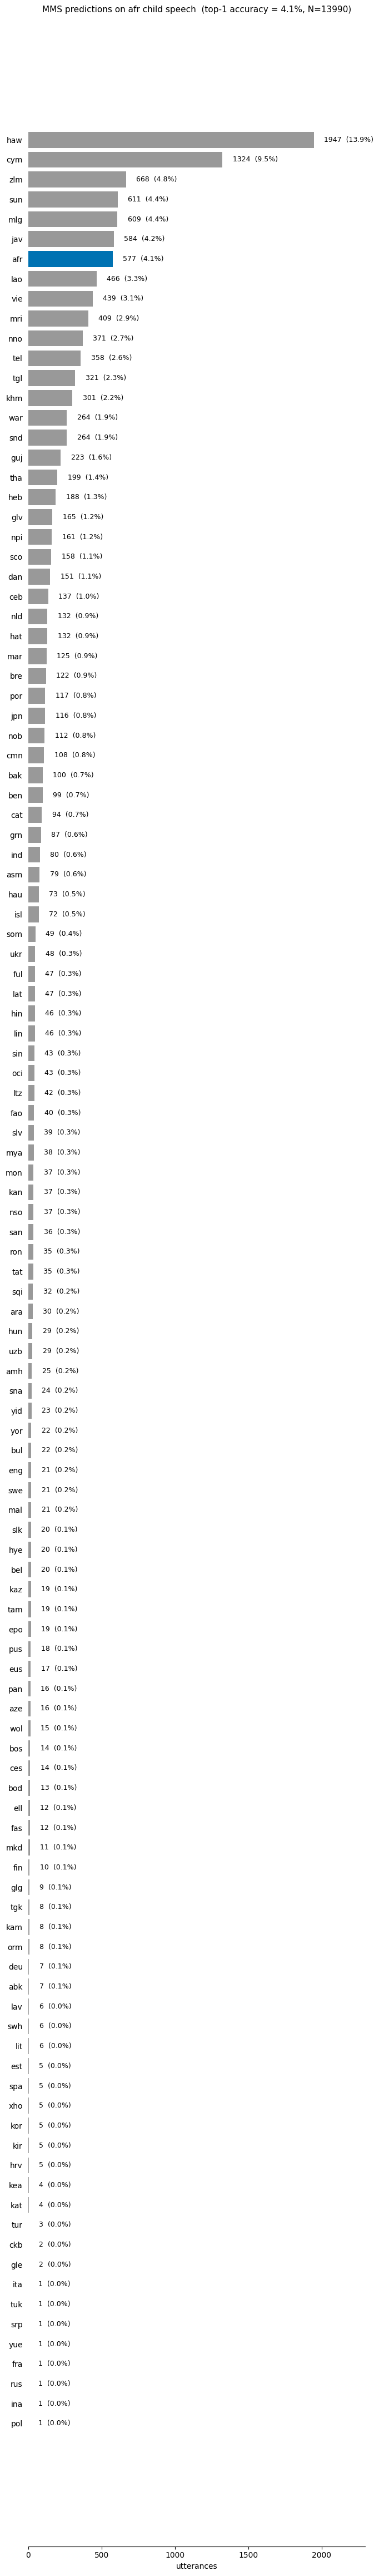

In [10]:
#RUN PREDICTIONS ON AFR AND SAVE THE RESULTS
#One file at a time, no batching
predictions = []
for path in tqdm(afr_child_df["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

#Each column holds a (language, probability) tuple
afr_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])
afr_results_df["true_lang"] = afr_child_df["true_lang"].values
afr_results_df["path"] = afr_child_df["path"].values

#Compute total accuracy
afr_results_df["correct"] = afr_results_df.apply(lambda row: row["top1"][0] == row["true_lang"], axis=1)
afr_accuracy = afr_results_df["correct"].mean()
print(f"Afrikaans Child Accuracy: {afr_accuracy:.4f}")

#Save prediction results to CSV
afr_results_df.to_csv("afr_child_predictions.csv", index=False)

#Plot predictions: 
plot_prediction_distribution(afr_results_df, "afr")
plt.tight_layout(); plt.savefig("afr_pred_dist.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
#RUN PREDICTIONS ON ENG AND SAVE RESULTS
#Same steps as for Afrikaans
predictions = []
for path in tqdm(eng_child_df["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

eng_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])
eng_results_df["true_lang"] = eng_child_df["true_lang"].values
eng_results_df["path"] = eng_child_df["path"].values

#Total accuracy
eng_results_df["correct"] = eng_results_df.apply(lambda row: row["top1"][0] == row["true_lang"], axis=1)
eng_accuracy = eng_results_df["correct"].mean()
print(f"English Child Accuracy: {eng_accuracy:.4f}")

#Save prediction results to CSV
eng_results_df.to_csv("eng_child_predictions.csv", index=False) 

#Plot predictions
plot_prediction_distribution(eng_results_df, "eng")
plt.tight_layout(); plt.savefig("eng_pred_dist.png", dpi=200, bbox_inches="tight")
plt.show()

Predicting language:   0%|          | 0/13160 [00:00<?, ?it/s]/Users/conarj/Library/Python/3.9/lib/python/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
Predicting language:  70%|███████   | 9243/13160 [1:04:47<27:27,  2.38it/s]  


KeyboardInterrupt: 

In [ ]:
#RUN PREDICTIONS ON NSO AND SAVE RESULTS
#Same steps as for Afrikaans
predictions = []
for path in tqdm(nso_child_df["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

nso_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])
nso_results_df["true_lang"] = nso_child_df["true_lang"].values
nso_results_df["path"] = nso_child_df["path"].values

#Total accuracy
nso_results_df["correct"] = nso_results_df.apply(lambda row: row["top1"][0] == row["true_lang"], axis=1)
nso_accuracy = nso_results_df["correct"].mean()
print(f"Northern Sotho Child Accuracy: {nso_accuracy:.4f}")

#Save prediction results to CSV
nso_results_df.to_csv("nso_child_predictions.csv", index=False) 
plot_prediction_distribution(nso_results_df, "nso")

#Plot predictions
plt.tight_layout(); plt.savefig("nso_pred_dist.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
#RUN PREDICTIONS ON XHOSA AND SAVE RESULTS
#Same steps as for Afrikaans
predictions = []
for path in tqdm(xho_child_df["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

xho_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])
xho_results_df["true_lang"] = xho_child_df["true_lang"].values
xho_results_df["path"] = xho_child_df["path"].values

#Total accuracy
xho_results_df["correct"] = xho_results_df.apply(lambda row: row["top1"][0] == row["true_lang"], axis=1)
xho_accuracy = xho_results_df["correct"].mean()
print(f"Xhosa Child Accuracy: {xho_accuracy:.4f}")

#Save prediction results to CSV
xho_results_df.to_csv("xho_child_predictions.csv", index=False) 
plot_prediction_distribution(xho_results_df, "xho")

#Plot predictions
plt.tight_layout(); plt.savefig("xho_pred_dist.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
#RUN PREDICTIONS ON DUTCH AND SAVE RESULTS 
#Same steps as for Afrikaans
predictions = []
for path in tqdm(nld_child_df["path"], desc="Predicting language"):
    predictions.append(predict_language(path))

nld_results_df = pd.DataFrame(predictions, columns=["top1", "top2", "top3"])
nld_results_df["true_lang"] = nld_child_df["true_lang"].values
nld_results_df["path"] = nld_child_df["path"].values

#Total accuracy
nld_results_df["correct"] = nld_results_df.apply(lambda row: row["top1"][0] == row["true_lang"], axis=1)
nld_accuracy = nld_results_df["correct"].mean()
print(f"Dutch Child Accuracy: {nld_accuracy:.4f}")

#Save prediction results to CSV
nld_results_df.to_csv("nld_child_predictions.csv", index=False) 
plot_prediction_distribution(nld_results_df, "nld")

#Plot predictions
plt.tight_layout(); plt.savefig("nld_pred_dist.png", dpi=200, bbox_inches="tight")
plt.show()